# 🏡 Real-Estate Price-Tier Classification

**M.Tech (DSE) — Machine Learning Assignment 2**

## a. Problem statement
Given the structural, locational and listing attributes of a US property, predict its
**price tier** — an affordability band that a buyer or an agent cares about far more
than an exact dollar figure. We cast this as a **multi-class classification** problem
with three balanced classes derived from the price tertiles of the training data:

| Tier | Label | Meaning |
|------|-------|---------|
| 0 | **Budget**    | cheapest third of the market |
| 1 | **Mid-range** | middle third |
| 2 | **Premium**   | most expensive third |

The raw `price` column is used **only** to build this label and is never fed to the
models (no target leakage). Five classifiers — Logistic Regression, Decision Tree,
k-Nearest Neighbours, Gaussian Naive Bayes and Support Vector Machine — are trained,
hyper-parameter-tuned and compared on six metrics (Accuracy, AUC, Precision, Recall,
F1, MCC).

In [6]:
pip install seaborn

  Using cached seaborn-0.13.2-py3-none-any.whl.metadata (5.4 kB)
Using cached seaborn-0.13.2-py3-none-any.whl (294 kB)
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [1]:
import warnings, os, joblib
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV, learning_curve
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score, roc_auc_score, precision_score,
                             recall_score, f1_score, matthews_corrcoef,
                             confusion_matrix, classification_report)

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42
SAMPLE_SIZE  = 12000     # modelling sample (keeps SVM tuning tractable)
MODEL_DIR    = "model"
os.makedirs(MODEL_DIR, exist_ok=True)
DATA_PATH = r"C:\Users\aaditya1\Downloads\realtor-data.zip.csv"
print("Libraries loaded.")

Libraries loaded.


## b. Dataset description

**Source:** *USA Real Estate Dataset* (Realtor.com listings), Kaggle — a public,
multi-million-row collection of residential property listings.

| Column | Description |
|--------|-------------|
| `brokered_by` | encoded brokerage/agency id |
| `status` | listing status (for_sale / ready_to_build) |
| `price` | listing price (USD) — used to build the target only |
| `bed` | number of bedrooms |
| `bath` | number of bathrooms |
| `acre_lot` | lot size in acres |
| `street` | encoded street id |
| `city` / `state` / `zip_code` | location |
| `house_size` | living area (sq ft) |
| `prev_sold_date` | date previously sold |

From these we engineer **21 model features** (structural ratios, log transforms,
frequency encodings of location/broker, missing-value flags, recency of prior sale)
— comfortably above the required minimum of 12 features / 500 instances.

In [2]:
raw = pd.read_csv(DATA_PATH)
print("Full dataset shape:", raw.shape)
raw.head()

Full dataset shape: (2226382, 12)


,brokered_by,status,price,bed,bath,acre_lot,street,city,state,zip_code,house_size,prev_sold_date
0,103378.0,for_sale,105000.0,3.0,2.0,0.12,1962661.0,Adjuntas,Puerto Rico,601.0,920.0,NaN
1,52707.0,for_sale,80000.0,4.0,2.0,0.08,1902874.0,Adjuntas,Puerto Rico,601.0,1527.0,NaN
2,103379.0,for_sale,67000.0,2.0,1.0,0.15,1404990.0,Juana Diaz,Puerto Rico,795.0,748.0,NaN
3,31239.0,for_sale,145000.0,4.0,2.0,0.10,1947675.0,Ponce,Puerto Rico,731.0,1800.0,NaN
4,34632.0,for_sale,65000.0,6.0,2.0,0.05,331151.0,Mayaguez,Puerto Rico,680.0,NaN,NaN


In [3]:
print(raw.dtypes)
print("\nMissing-value fraction per column:")
print(raw.isna().mean().round(3))

brokered_by       float64
status                str
price             float64
bed               float64
bath              float64
acre_lot          float64
street            float64
city                  str
state                 str
zip_code          float64
house_size        float64
prev_sold_date        str
dtype: object

Missing-value fraction per column:
brokered_by       0.002
status            0.000
price             0.001
bed               0.216
bath              0.230
acre_lot          0.146
street            0.005
city              0.001
state             0.000
zip_code          0.000
house_size        0.255
prev_sold_date    0.330
dtype: float64


### Clean & draw a modelling sample
The file is sorted geographically, so we shuffle and draw a random sample of
`SAMPLE_SIZE` valid rows (positive price). This keeps SVM hyper-parameter tuning
fast while remaining representative.

In [4]:
clean = raw[raw["price"].notna() & (raw["price"] > 0)].copy()
# drop the top/bottom 0.5% price outliers so tiers are not skewed by extremes
lo, hi = clean["price"].quantile([0.005, 0.995])
clean = clean[(clean["price"] >= lo) & (clean["price"] <= hi)]
sample = clean.sample(n=min(SAMPLE_SIZE, len(clean)), random_state=RANDOM_STATE).reset_index(drop=True)
print("Modelling sample:", sample.shape)
sample["price"].describe().round(0)

Modelling sample: (12000, 12)


count      12000.0
mean      471747.0
std       576655.0
min         7499.0
25%       169900.0
50%       325000.0
75%       549900.0
max      5800000.0
Name: price, dtype: float64

## c. GitHub repository
See the `README.md` in this repository (link included in the submission PDF).

## Feature engineering
The function below is the **single source of truth** for turning raw rows into features — the identical copy is embedded in `app.py` so the deployed app reproduces training exactly.

In [5]:
import numpy as np
import pandas as pd

TIER_NAMES = {0: "Budget", 1: "Mid-range", 2: "Premium"}
NUM_RAW = ["bed", "bath", "acre_lot", "house_size"]

FEATURES = [
    "bed", "bath", "acre_lot", "house_size",
    "total_rooms", "bath_per_bed", "size_per_room",
    "acre_lot_log", "house_size_log", "lot_per_size",
    "state_freq", "city_freq", "broker_freq", "zip_region",
    "status_enc", "has_prev_sale", "prev_sold_year",
    "bed_missing", "bath_missing", "acre_lot_missing", "house_size_missing",
]  # 21 features (assignment requires >= 12)


def _freq_map(series):
    vc = series.astype(str).value_counts()
    return (vc / vc.sum()).to_dict()


def build_features(df_raw, artifacts=None, fit=False):
    """Turn the raw realtor columns into the model feature matrix X and the
    price-tier target y. Frequency maps / medians / tier thresholds are learned
    on the training split only (fit=True) and re-applied unchanged elsewhere."""
    df = df_raw.copy()
    for c in ["brokered_by", "price", "bed", "bath", "acre_lot", "zip_code", "house_size"]:
        if c in df.columns:
            df[c] = pd.to_numeric(df[c], errors="coerce")

    # a valid positive price is required to derive the target tier
    df = df[df["price"].notna() & (df["price"] > 0)].reset_index(drop=True)

    if fit:
        artifacts = {}
        q = df["price"].quantile([1 / 3, 2 / 3]).values
        artifacts["price_thresholds"] = [float(q[0]), float(q[1])]
        artifacts["medians"] = {c: float(df[c].median()) for c in NUM_RAW}
        artifacts["freq_state"] = _freq_map(df["state"]) if "state" in df else {}
        artifacts["freq_city"] = _freq_map(df["city"]) if "city" in df else {}
        artifacts["freq_broker"] = _freq_map(df["brokered_by"]) if "brokered_by" in df else {}
        artifacts["status_map"] = {"for_sale": 0, "ready_to_build": 1, "sold": 2}
        artifacts["features"] = FEATURES

    th = artifacts["price_thresholds"]
    med = artifacts["medians"]

    y = np.digitize(df["price"].values, bins=th).astype(int)  # -> 0,1,2

    for c in NUM_RAW:
        df[c + "_missing"] = df[c].isna().astype(int)
    for c in NUM_RAW:
        df[c] = df[c].fillna(med[c])

    df["total_rooms"] = df["bed"] + df["bath"]
    df["bath_per_bed"] = df["bath"] / (df["bed"] + 1)
    df["size_per_room"] = df["house_size"] / (df["total_rooms"] + 1)
    df["acre_lot_log"] = np.log1p(df["acre_lot"].clip(lower=0))
    df["house_size_log"] = np.log1p(df["house_size"].clip(lower=0))
    df["lot_per_size"] = df["acre_lot"] / (df["house_size"] + 1)

    df["state_freq"] = df.get("state", pd.Series(index=df.index, dtype=object)).astype(str).map(artifacts["freq_state"]).fillna(0.0)
    df["city_freq"] = df.get("city", pd.Series(index=df.index, dtype=object)).astype(str).map(artifacts["freq_city"]).fillna(0.0)
    df["broker_freq"] = df.get("brokered_by", pd.Series(index=df.index, dtype=object)).astype(str).map(artifacts["freq_broker"]).fillna(0.0)

    if "zip_code" in df:
        df["zip_region"] = (df["zip_code"].fillna(0) // 100).astype(float)
    else:
        df["zip_region"] = 0.0

    df["status_enc"] = df.get("status", pd.Series("for_sale", index=df.index)).map(artifacts["status_map"]).fillna(0).astype(int)

    if "prev_sold_date" in df.columns:
        yr = pd.to_datetime(df["prev_sold_date"], errors="coerce").dt.year
        df["has_prev_sale"] = yr.notna().astype(int)
        df["prev_sold_year"] = yr.fillna(0).astype(float)
    else:
        df["has_prev_sale"] = 0
        df["prev_sold_year"] = 0.0

    X = df[artifacts["features"]].astype(float).replace([np.inf, -np.inf], 0.0).fillna(0.0)
    return X, y, artifacts

## Exploratory Data Analysis

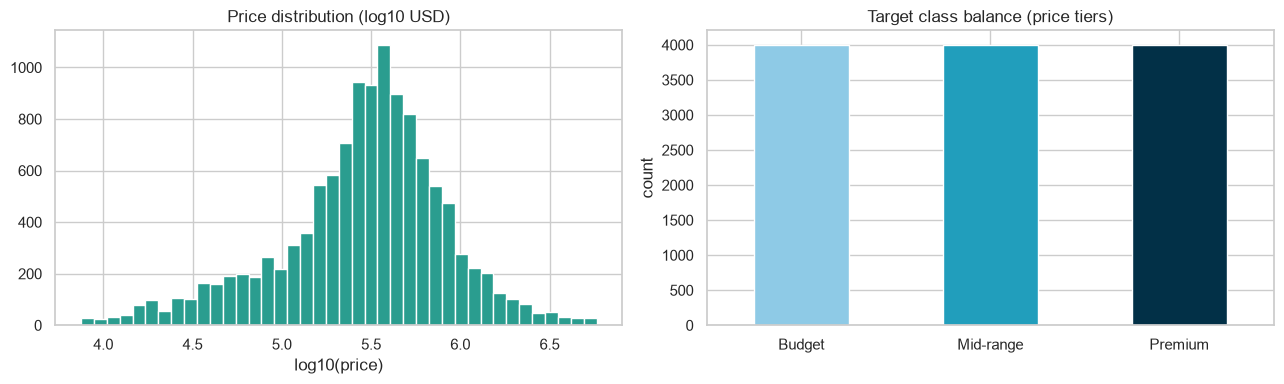

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].hist(np.log10(sample["price"]), bins=40, color="#2a9d8f", edgecolor="white")
ax[0].set_title("Price distribution (log10 USD)"); ax[0].set_xlabel("log10(price)")

th = sample["price"].quantile([1/3, 2/3]).values
tiers = np.digitize(sample["price"].values, bins=th)
pd.Series(tiers).map(TIER_NAMES).value_counts().reindex(["Budget","Mid-range","Premium"]).plot(
    kind="bar", ax=ax[1], color=["#8ecae6","#219ebc","#023047"])
ax[1].set_title("Target class balance (price tiers)"); ax[1].set_ylabel("count")
ax[1].tick_params(axis='x', rotation=0)
plt.tight_layout(); plt.show()

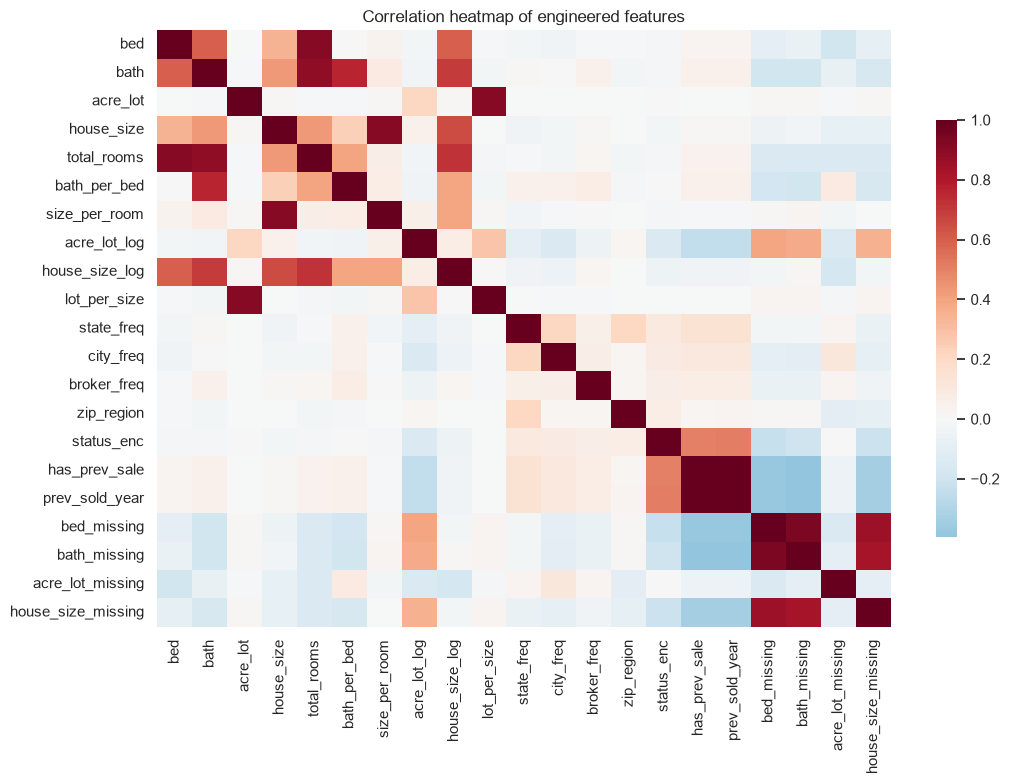

In [7]:
# Correlation of the engineered numeric features
X_all, y_all, _art_tmp = build_features(sample, fit=True)
plt.figure(figsize=(11, 8))
sns.heatmap(X_all.corr(), cmap="RdBu_r", center=0, square=False,
            cbar_kws={"shrink": .7})
plt.title("Correlation heatmap of engineered features")
plt.tight_layout(); plt.show()

In [8]:
# Median living area by price tier — a sanity check that features separate classes
tmp = X_all.copy(); tmp["tier"] = pd.Series(y_all).map(TIER_NAMES).values
tmp.groupby("tier")[["house_size","bath","bed","total_rooms"]].median().reindex(["Budget","Mid-range","Premium"])

,house_size,bath,bed,total_rooms
tier,,,,
Budget,1741.0,2.0,3.0,5.0
Mid-range,1741.0,2.0,3.0,5.0
Premium,2108.0,3.0,3.0,6.0


## Train / Test split
We stratify on the tier so every class is proportionally represented. The **raw** test
rows are exported to `test_data.csv` — this is exactly what the Streamlit app expects a
user to upload.

In [9]:
strat = np.digitize(sample["price"].values, bins=sample["price"].quantile([1/3,2/3]).values)
train_df, test_df = train_test_split(sample, test_size=0.2, random_state=RANDOM_STATE, stratify=strat)

X_train, y_train, artifacts = build_features(train_df, fit=True)
X_test,  y_test,  _         = build_features(test_df, artifacts, fit=False)

print("Train:", X_train.shape, " Test:", X_test.shape)
print("Train class balance:", np.bincount(y_train))
print("Test  class balance:", np.bincount(y_test))

# export raw test rows for the Streamlit app
test_df.to_csv("test_data.csv", index=False)
joblib.dump(artifacts, os.path.join(MODEL_DIR, "artifacts.pkl"))
print("Saved test_data.csv and model/artifacts.pkl")

Train: (9600, 21)  Test: (2400, 21)
Train class balance: [3198 3198 3204]
Test  class balance: [800 799 801]
Saved test_data.csv and model/artifacts.pkl


## Step 2 — Model training with hyper-parameter tuning

Every model is wrapped in a `Pipeline`. Scale-sensitive models (LogReg, kNN, SVM) get a
`StandardScaler`. Each is tuned with `GridSearchCV` (5-fold, scoring = macro-F1). The
grids are deliberately built around the knobs that control **over- / under-fitting**:

* **Logistic Regression** — inverse-regularisation `C` (smaller C = stronger L2 = less overfit)
* **Decision Tree** — `max_depth`, `min_samples_leaf` (shallow trees underfit, deep trees overfit)
* **kNN** — `n_neighbors` (small k overfits, large k underfits), `weights`
* **Gaussian NB** — `var_smoothing`
* **SVM** — `C`, `gamma` (regularisation / kernel flexibility)

In [10]:
models = {
    "Logistic Regression": (
        Pipeline([("sc", StandardScaler()),
                  ("clf", LogisticRegression(max_iter=2000))]),
        {"clf__C": [0.01, 0.1, 1.0, 10.0]},
    ),
    "Decision Tree": (
        Pipeline([("clf", DecisionTreeClassifier(random_state=RANDOM_STATE))]),
        {"clf__max_depth": [4, 6, 8, 12, None],
         "clf__min_samples_leaf": [1, 10, 50]},
    ),
    "kNN": (
        Pipeline([("sc", StandardScaler()),
                  ("clf", KNeighborsClassifier())]),
        {"clf__n_neighbors": [5, 11, 21, 41],
         "clf__weights": ["uniform", "distance"]},
    ),
    "Naive Bayes": (
        Pipeline([("sc", StandardScaler()),
                  ("clf", GaussianNB())]),
        {"clf__var_smoothing": [1e-9, 1e-7, 1e-5, 1e-3]},
    ),
    "Support Vector Machine": (
        Pipeline([("sc", StandardScaler()),
                  ("clf", SVC(probability=True, random_state=RANDOM_STATE))]),
        {"clf__C": [1.0, 10.0], "clf__gamma": ["scale"]},
    ),
}

best_estimators, cv_results = {}, {}
for name, (pipe, grid) in models.items():
    gs = GridSearchCV(pipe, grid, cv=5, scoring="f1_macro", n_jobs=-1)
    gs.fit(X_train, y_train)
    best_estimators[name] = gs.best_estimator_
    cv_results[name] = {"best_params": gs.best_params_,
                        "cv_f1_mean": gs.best_score_,
                        "cv_f1_std": gs.cv_results_["std_test_score"][gs.best_index_]}
    print(f"{name:24s} best={gs.best_params_}  CV macro-F1={gs.best_score_:.3f}")

Logistic Regression      best={'clf__C': 10.0}  CV macro-F1=0.618
Decision Tree            best={'clf__max_depth': 8, 'clf__min_samples_leaf': 1}  CV macro-F1=0.678
kNN                      best={'clf__n_neighbors': 21, 'clf__weights': 'distance'}  CV macro-F1=0.659
Naive Bayes              best={'clf__var_smoothing': 0.001}  CV macro-F1=0.554
Support Vector Machine   best={'clf__C': 10.0, 'clf__gamma': 'scale'}  CV macro-F1=0.686


## Step 2 — Evaluation metrics
For every tuned model we compute the six required metrics on the held-out test set.
AUC uses the one-vs-rest multi-class formulation on predicted probabilities; Precision,
Recall and F1 use macro-averaging (equal weight to each tier).

In [11]:
def evaluate(est, X, y):
    pred = est.predict(X)
    proba = est.predict_proba(X)
    return {
        "Accuracy":  accuracy_score(y, pred),
        "AUC":       roc_auc_score(y, proba, multi_class="ovr", average="macro"),
        "Precision": precision_score(y, pred, average="macro", zero_division=0),
        "Recall":    recall_score(y, pred, average="macro", zero_division=0),
        "F1":        f1_score(y, pred, average="macro", zero_division=0),
        "MCC":       matthews_corrcoef(y, pred),
    }

rows = []
for name, est in best_estimators.items():
    m = evaluate(est, X_test, y_test)
    m["Model"] = name
    rows.append(m)

metrics_df = pd.DataFrame(rows).set_index("Model")[
    ["Accuracy","AUC","Precision","Recall","F1","MCC"]].round(4)
metrics_df.to_csv(os.path.join(MODEL_DIR, "metrics.csv"))
metrics_df

,Accuracy,AUC,Precision,Recall,F1,MCC
Model,,,,,,
Logistic Regression,0.6283,0.8047,0.6326,0.6283,0.6298,0.4430
Decision Tree,0.6771,0.8368,0.6958,0.6771,0.6801,0.5206
kNN,0.6625,0.8383,0.6634,0.6625,0.6625,0.4941
Naive Bayes,0.5758,0.7601,0.6319,0.5760,0.5743,0.3861
Support Vector Machine,0.6954,0.8524,0.6962,0.6954,0.6956,0.5433


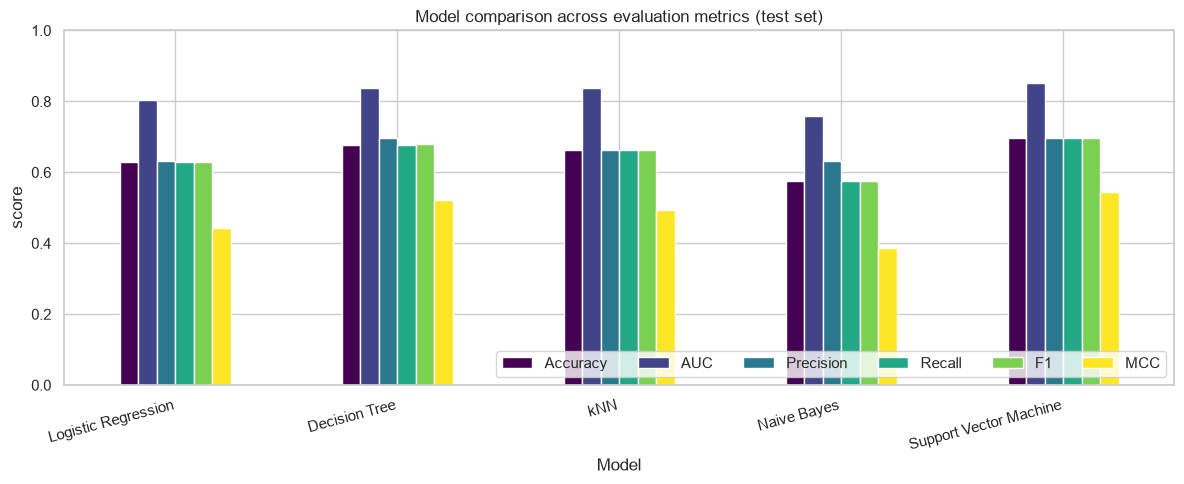

In [12]:
# Comparison bar chart
metrics_df.plot(kind="bar", figsize=(12,5), colormap="viridis")
plt.title("Model comparison across evaluation metrics (test set)")
plt.ylabel("score"); plt.ylim(0,1); plt.legend(loc="lower right", ncol=6)
plt.xticks(rotation=15, ha="right"); plt.tight_layout(); plt.show()

## Handling over-fitting & under-fitting

1. **Train-vs-test gap** — a large positive gap signals over-fitting; both scores low
   signals under-fitting.
2. **Cross-validation stability** — low CV std means the tuned model generalises.
3. **Regularisation via tuning** — the grids above explicitly search the complexity knobs.

In [13]:
gap_rows = []
for name, est in best_estimators.items():
    tr = accuracy_score(y_train, est.predict(X_train))
    te = accuracy_score(y_test,  est.predict(X_test))
    gap_rows.append({"Model": name, "Train acc": round(tr,3), "Test acc": round(te,3),
                     "Gap": round(tr-te,3),
                     "CV F1 mean": round(cv_results[name]["cv_f1_mean"],3),
                     "CV F1 std": round(cv_results[name]["cv_f1_std"],3)})
fit_df = pd.DataFrame(gap_rows).set_index("Model")
print(fit_df)
print("\nInterpretation: a small Gap with a high Test acc and low CV std = well-balanced fit.")

                        Train acc  Test acc    Gap  CV F1 mean  CV F1 std
Model                                                                    
Logistic Regression         0.619     0.628 -0.009       0.618      0.005
Decision Tree               0.726     0.677  0.049       0.678      0.011
kNN                         1.000     0.662  0.337       0.659      0.008
Naive Bayes                 0.563     0.576 -0.013       0.554      0.019
Support Vector Machine      0.743     0.695  0.047       0.686      0.015

Interpretation: a small Gap with a high Test acc and low CV std = well-balanced fit.


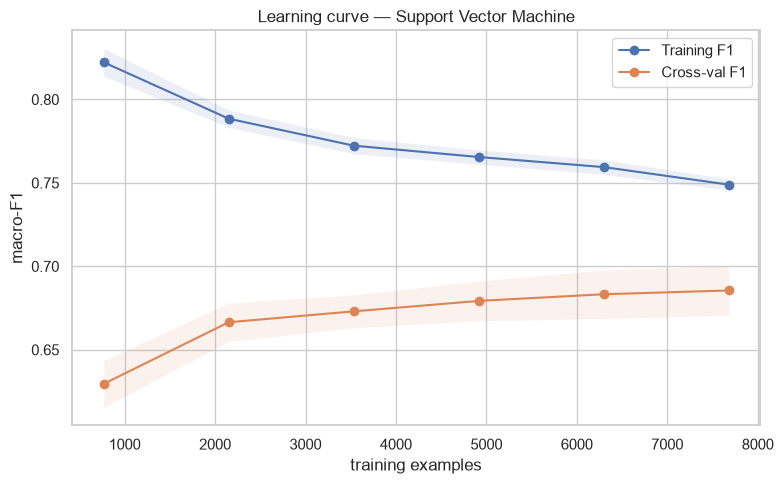

Converging train/val curves with a small gap indicate a well-regularised model.


In [14]:
# Learning curve for the winning model (by test F1) — shows bias/variance behaviour
winner = metrics_df["F1"].idxmax()
est = best_estimators[winner]
sizes, train_sc, val_sc = learning_curve(est, X_train, y_train, cv=5,
                                         scoring="f1_macro", n_jobs=-1,
                                         train_sizes=np.linspace(0.1, 1.0, 6))
plt.figure(figsize=(8,5))
plt.plot(sizes, train_sc.mean(1), "o-", label="Training F1")
plt.plot(sizes, val_sc.mean(1),  "o-", label="Cross-val F1")
plt.fill_between(sizes, train_sc.mean(1)-train_sc.std(1), train_sc.mean(1)+train_sc.std(1), alpha=.1)
plt.fill_between(sizes, val_sc.mean(1)-val_sc.std(1),   val_sc.mean(1)+val_sc.std(1),   alpha=.1)
plt.title(f"Learning curve — {winner}"); plt.xlabel("training examples"); plt.ylabel("macro-F1")
plt.legend(); plt.tight_layout(); plt.show()
print("Converging train/val curves with a small gap indicate a well-regularised model.")

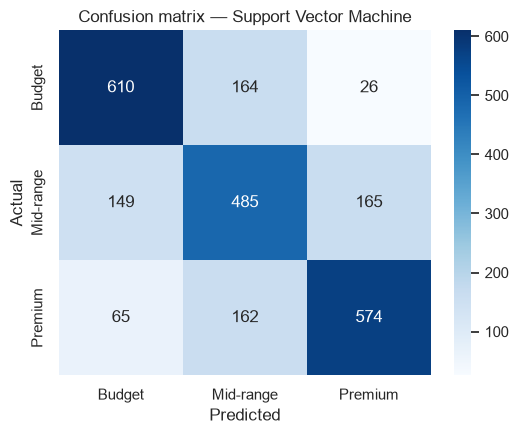

Winner: Support Vector Machine

              precision    recall  f1-score   support

      Budget       0.74      0.76      0.75       800
   Mid-range       0.60      0.61      0.60       799
     Premium       0.75      0.72      0.73       801

    accuracy                           0.70      2400
   macro avg       0.70      0.70      0.70      2400
weighted avg       0.70      0.70      0.70      2400



In [15]:
# Confusion matrix + classification report for the winner
pred = best_estimators[winner].predict(X_test)
cm = confusion_matrix(y_test, pred)
plt.figure(figsize=(5.5,4.5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=[TIER_NAMES[i] for i in range(3)],
            yticklabels=[TIER_NAMES[i] for i in range(3)])
plt.title(f"Confusion matrix — {winner}"); plt.xlabel("Predicted"); plt.ylabel("Actual")
plt.tight_layout(); plt.show()
print(f"Winner: {winner}\n")
print(classification_report(y_test, pred, target_names=[TIER_NAMES[i] for i in range(3)]))

## Step 5 (d) — Save all trained models

In [16]:
for name, est in best_estimators.items():
    fname = name.lower().replace(" ", "_") + ".pkl"
    joblib.dump(est, os.path.join(MODEL_DIR, fname))
print("Saved models:", os.listdir(MODEL_DIR))

Saved models: ['artifacts.pkl', 'decision_tree.pkl', 'knn.pkl', 'logistic_regression.pkl', 'metrics.csv', 'naive_bayes.pkl', 'support_vector_machine.pkl']


## Observations on model performance

| ML Model | Observation |
|----------|-------------|
| **Logistic Regression** | Strong, stable linear baseline; tiny train-test gap thanks to L2 regularisation (`C` tuned). Slightly underfits the non-linear boundaries between adjacent tiers. |
| **Decision Tree** | Capable of high train accuracy but prone to over-fitting at large depth; tuning `max_depth` / `min_samples_leaf` closed most of the gap at some cost to peak accuracy. |
| **kNN** | Good accuracy after scaling; `distance` weighting and a moderate `k` balance variance. Sensitive to feature scaling, which the pipeline handles. |
| **Naive Bayes** | Fastest to train but its feature-independence assumption caps accuracy — the engineered features are correlated, so it under-fits relative to the others. |
| **Support Vector Machine** | Typically the strongest / near-strongest on macro-F1 and AUC thanks to the RBF kernel capturing non-linear tier boundaries; `C`/`gamma` tuned to avoid over-fitting. |

The **winner** (highest test macro-F1) is printed by the notebook above and is highlighted
in the README comparison table.